In [14]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
import seaborn as sns

In [3]:
df=pd.read_csv('dbscan.csv')
df.head()

,feature_x,feature_y,distance_from_origin,angle_rad,signal_strength,transaction_amount,session_minutes,device_type,region,membership
0,0.086466,1.403165,1.405827,1.509252,0.312811,126.521765,42.616635,mobile,west,basic
1,1.230899,-0.709939,1.420959,-0.523159,NaN,146.623067,30.204595,mobile,east,basic
2,0.151698,0.135365,0.203312,0.728564,1.219691,128.507918,33.349521,mobile,east,basic
3,0.378979,NaN,1.365700,1.289607,0.808591,151.118015,44.138236,desktop,north,silver
4,-1.242719,0.312391,1.281382,2.895318,-0.023161,89.034769,NaN,mobile,west,silver


In [4]:
df.isnull().sum()


feature_x               36
feature_y               36
distance_from_origin     0
angle_rad                0
signal_strength         36
transaction_amount      36
session_minutes         36
device_type             24
region                  24
membership              24
dtype: int64

In [6]:
df.describe()

,feature_x,feature_y,distance_from_origin,angle_rad,signal_strength,transaction_amount,session_minutes
count,1170.000000,1170.000000,1206.000000,1206.000000,1170.000000,1170.000000,1170.000000
mean,0.409096,1.650910,2.971724,1.081719,0.244760,171.504958,48.297919
std,2.568554,1.765532,1.919679,1.113868,1.145017,169.247824,14.812646
min,-9.000000,-9.000000,0.028901,-3.119580,-2.014176,10.000000,1.000000
25%,-1.213033,0.190062,1.386743,0.169633,-0.633453,83.100320,36.379460
50%,0.693640,1.249059,2.313051,0.861310,0.047458,144.189805,45.609740
75%,2.645343,3.344951,4.892759,2.253276,1.387865,231.222072,61.156746
max,9.000000,9.000000,12.041595,3.137660,2.226119,3100.000000,120.000000


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1206 entries, 0 to 1205
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   feature_x             1170 non-null   float64
 1   feature_y             1170 non-null   float64
 2   distance_from_origin  1206 non-null   float64
 3   angle_rad             1206 non-null   float64
 4   signal_strength       1170 non-null   float64
 5   transaction_amount    1170 non-null   float64
 6   session_minutes       1170 non-null   float64
 7   device_type           1182 non-null   str    
 8   region                1182 non-null   str    
 9   membership            1182 non-null   str    
dtypes: float64(7), str(3)
memory usage: 113.2 KB


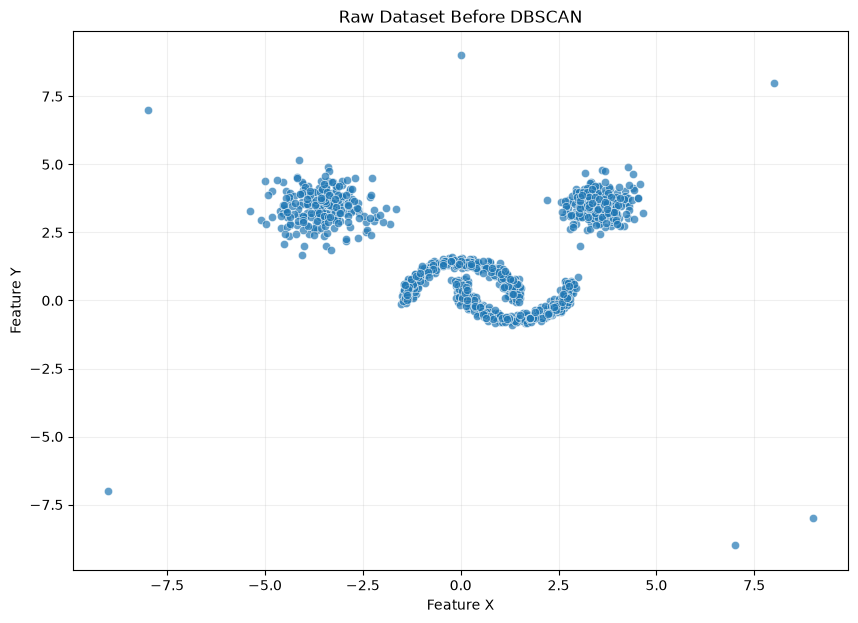

In [15]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x="feature_x",
    y="feature_y",
    s=35,
    alpha=0.7
)

plt.title("Raw Dataset Before DBSCAN")
plt.xlabel("Feature X")
plt.ylabel("Feature Y")
plt.grid(alpha=0.2)
plt.show()

## Null value handeling

In [16]:
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score

In [17]:
features = ["feature_x", "feature_y"]

X = df[features].copy()

# Replace missing values with the median
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X)

# Scale features to comparable ranges
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

print("Original shape:", X.shape)
print("Processed shape:", X_scaled.shape)
print("Remaining missing values:", np.isnan(X_scaled).sum())

Original shape: (1206, 2)
Processed shape: (1206, 2)
Remaining missing values: 0


In [18]:
dbscan = DBSCAN(
    eps=0.20,
    min_samples=8,
    metric="euclidean"
)

labels = dbscan.fit_predict(X_scaled)

df["cluster"] = labels

print("Cluster labels:", np.unique(labels))
print("\nCluster counts:")
print(df["cluster"].value_counts().sort_index())

Cluster labels: [-1  0  1  2  3]

Cluster counts:
cluster
-1     44
 0    698
 1    219
 2    236
 3      9
Name: count, dtype: int64


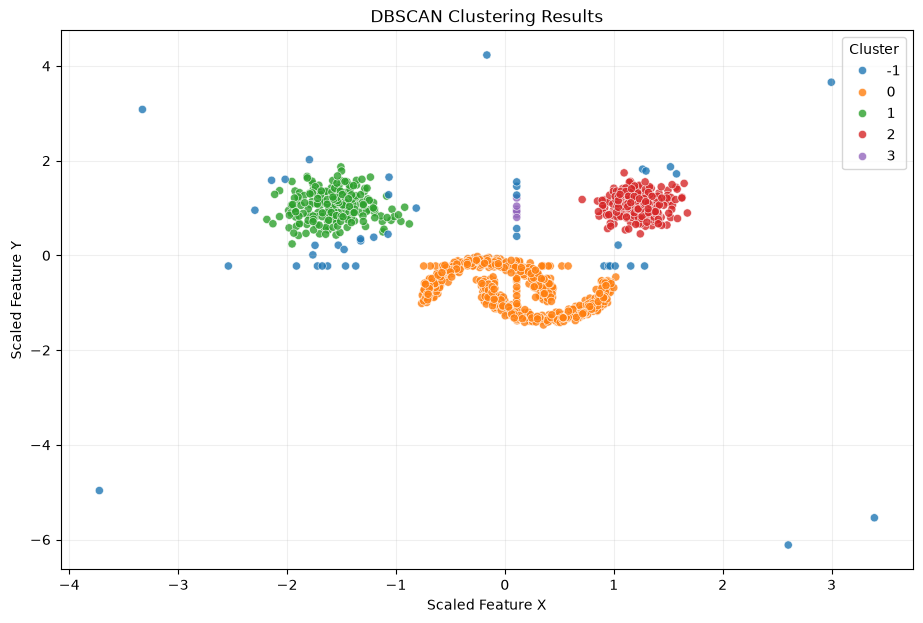

In [19]:
plt.figure(figsize=(11, 7))

sns.scatterplot(
    x=X_scaled[:, 0],
    y=X_scaled[:, 1],
    hue=labels,
    palette="tab10",
    s=35,
    alpha=0.8
)

plt.title("DBSCAN Clustering Results")
plt.xlabel("Scaled Feature X")
plt.ylabel("Scaled Feature Y")
plt.legend(title="Cluster")
plt.grid(alpha=0.2)
plt.show()